## MTL Trajet: 17 Weekday Work Destination Flows (Flag 17)

### Dataset Overview
Weekday work trajectories divided into central-bound and outward flows, with destination location, departure time, transport mode, route corridor, and point-level GPS data.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Investigate spatial and mobility differences among weekday work trajectories with different destination locations.

Role: Urban mobility-pattern analyst


Category: Weekday work trajectories divided into central-bound and outward flows, with destination location, departure time, transport mode, route corridor, and point-level GPS data.

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What shares of weekday work trajectories flow toward central versus peripheral employment?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

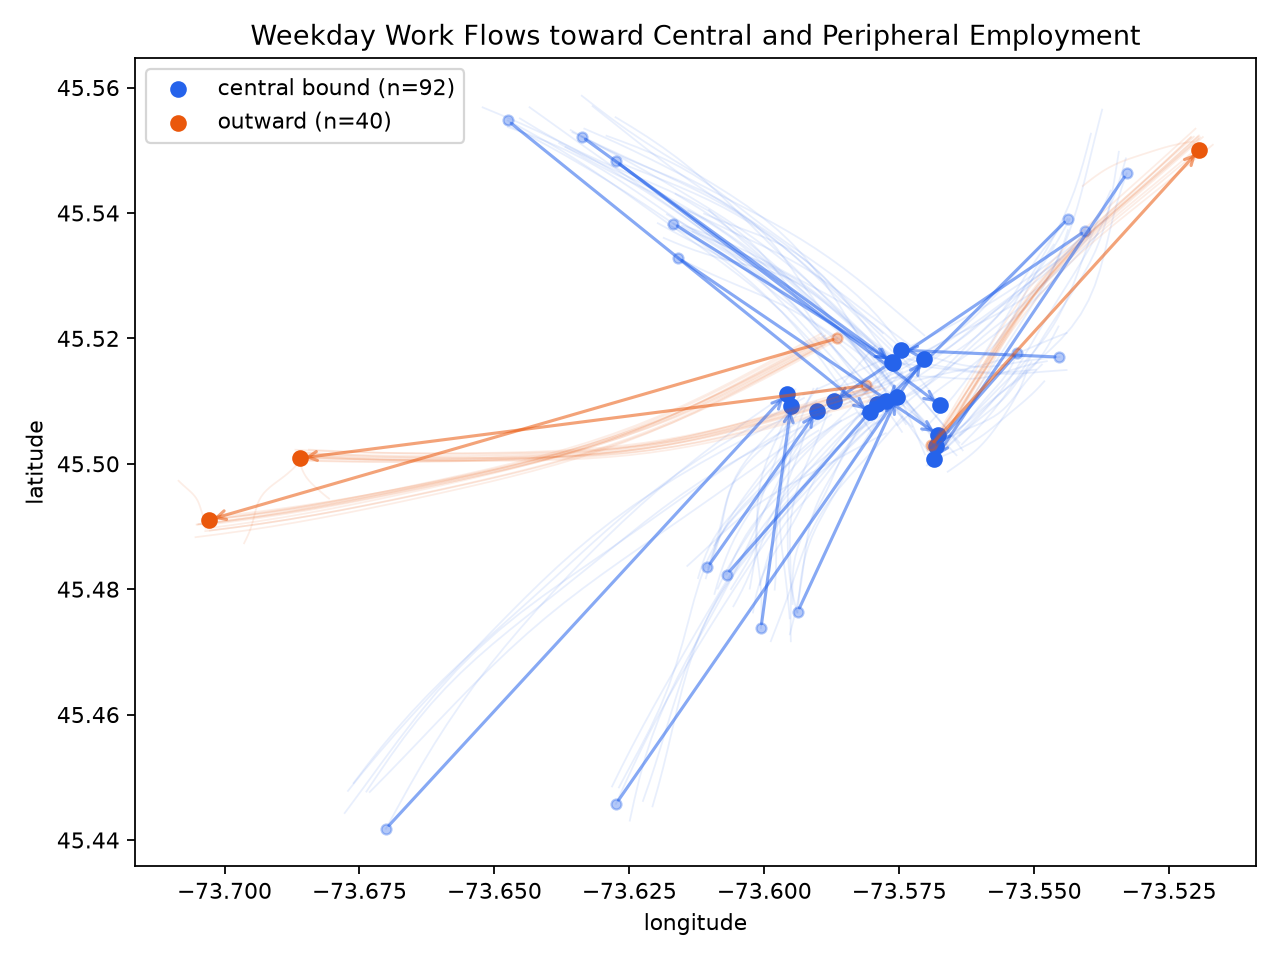

In [ ]:
df.groupby(['flow_group','destination_location']).size()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/central_and_outward_work_flows.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "weekday_work_flow",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Central-bound and Outward Work Flows",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/central_and_outward_work_flows.png"
  },
  "question": "What shares of weekday work trajectories flow toward central versus peripheral employment?",
  "code": "df.groupby(['flow_group','destination_location']).size()",
  "insight": "Morning work trajectories show a strong inward flow toward central employment areas, while a smaller outward-flow group ends in peripheral employment zones.",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_id",
    "gps_position",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How do mode composition and distance differ between central-bound and outward work trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

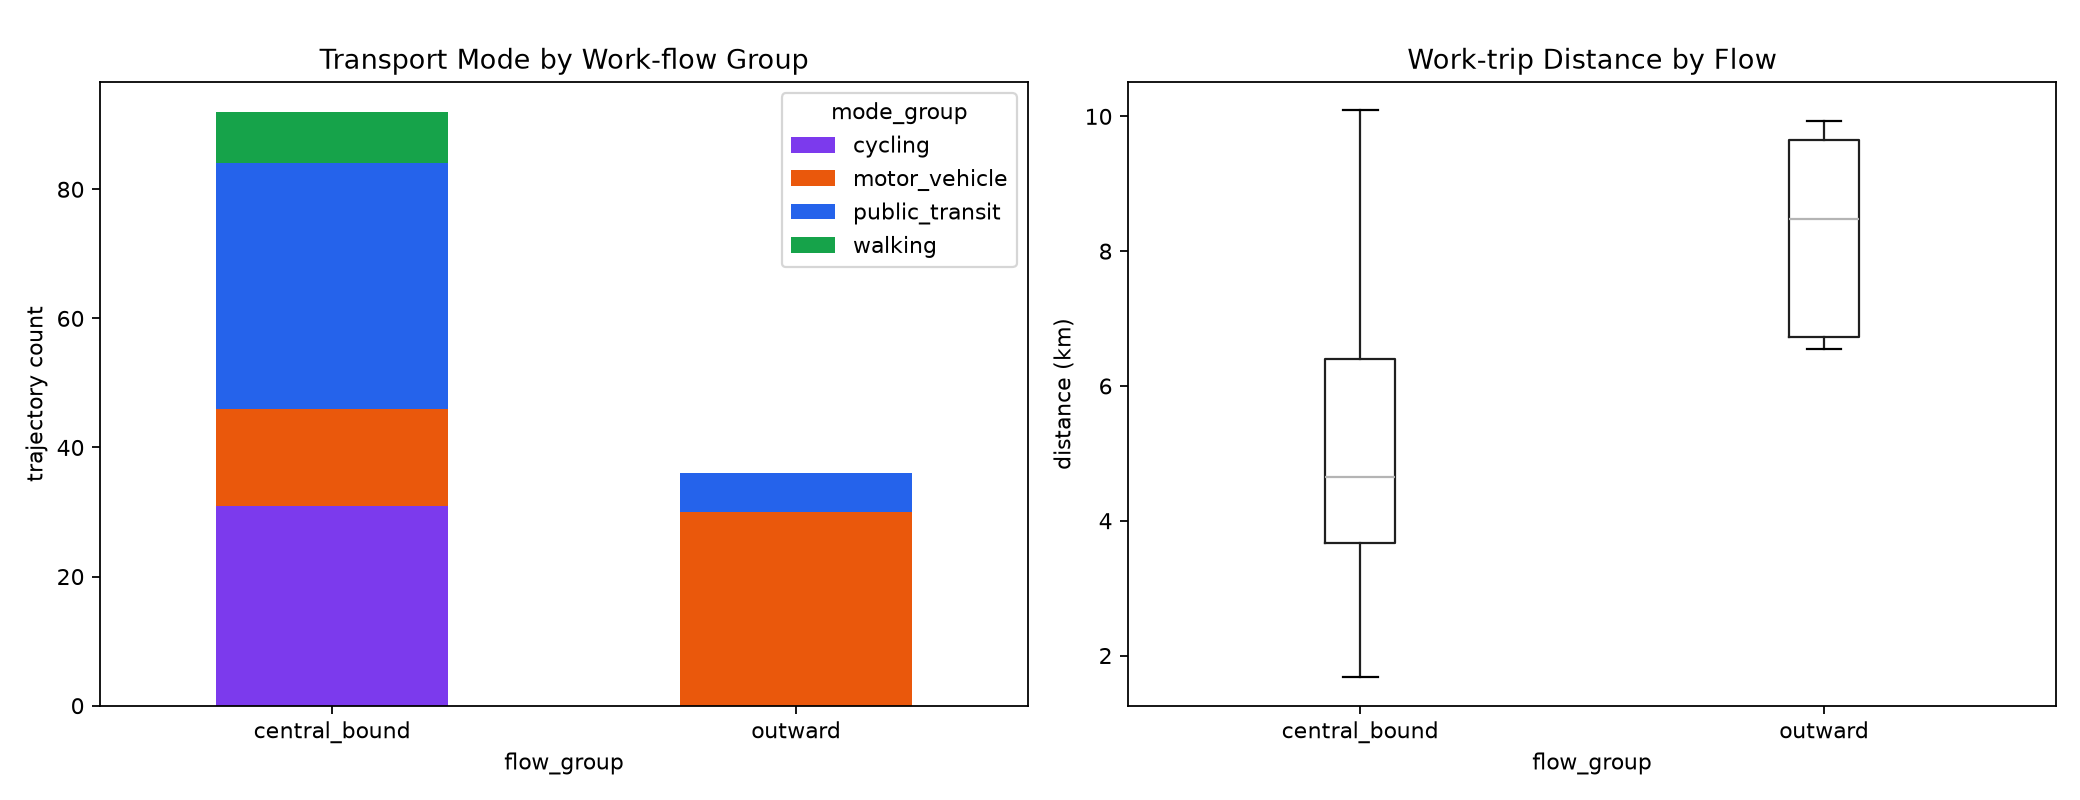

In [ ]:
pd.crosstab(df.flow_group,df.mode_group); df.groupby('flow_group').distance_km.agg(['median','mean'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/flow_mode_and_distance.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "work_flow_mode_distance",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Mode and Distance by Work-flow Group",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/flow_mode_and_distance.png"
  },
  "question": "How do mode composition and distance differ between central-bound and outward work trips?",
  "code": "pd.crosstab(df.flow_group,df.mode_group); df.groupby('flow_group').distance_km.agg(['median','mean'])",
  "insight": "Outward commuters rely more on motor vehicles and travel longer distances; central-bound commuters include more public-transit and cycling trajectories.",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "transport_mode"
  ]
}

### **Question 3**: Do outward trips depart earlier and reuse fewer corridors more intensively?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

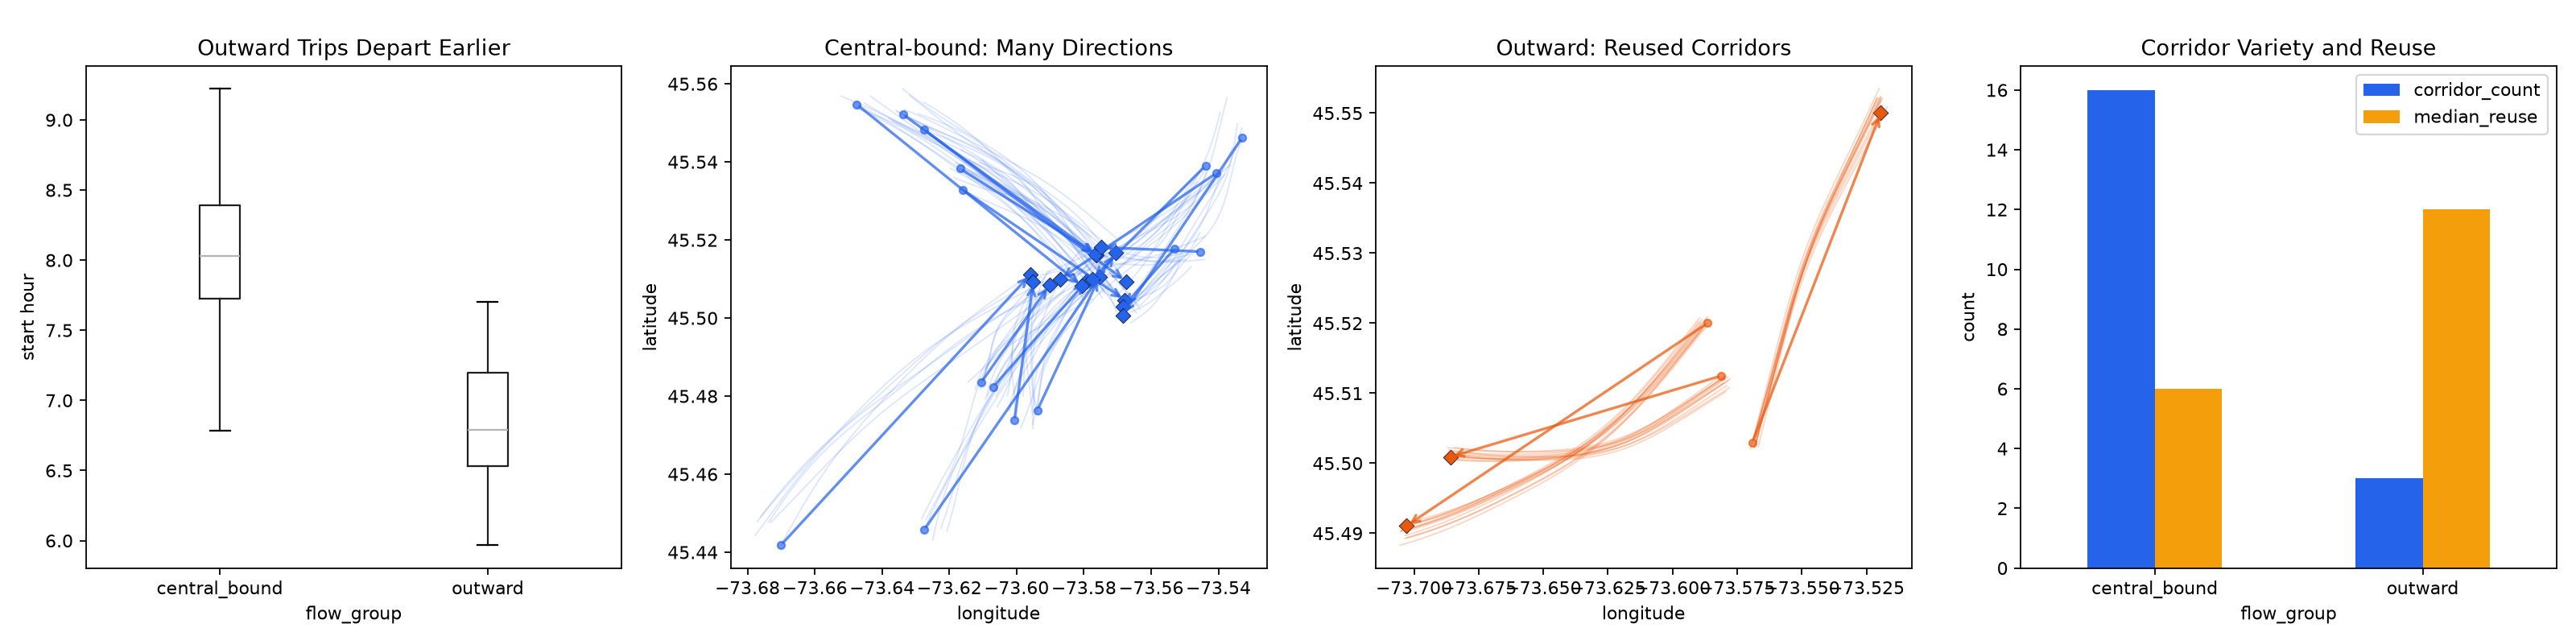

In [ ]:
df.groupby('flow_group').agg(start_hour_median=('start_hour','median'),corridors=('corridor_id','nunique'),reuse=('corridor_reuse_count','median'))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/flow_departure_and_corridor_overlap.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "work_flow_departure_corridor",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Departure Time and Corridor Reuse",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/flow_departure_and_corridor_overlap.png"
  },
  "question": "Do outward trips depart earlier and reuse fewer corridors more intensively?",
  "code": "df.groupby('flow_group').agg(start_hour_median=('start_hour','median'),corridors=('corridor_id','nunique'),reuse=('corridor_reuse_count','median'))",
  "insight": "Outward work trips depart earlier and follow fewer recurring radial corridors, producing greater route overlap than central-bound work trips.",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### **Question 4**: Which outward work trips depart from the usual motorized, longer-distance pattern?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

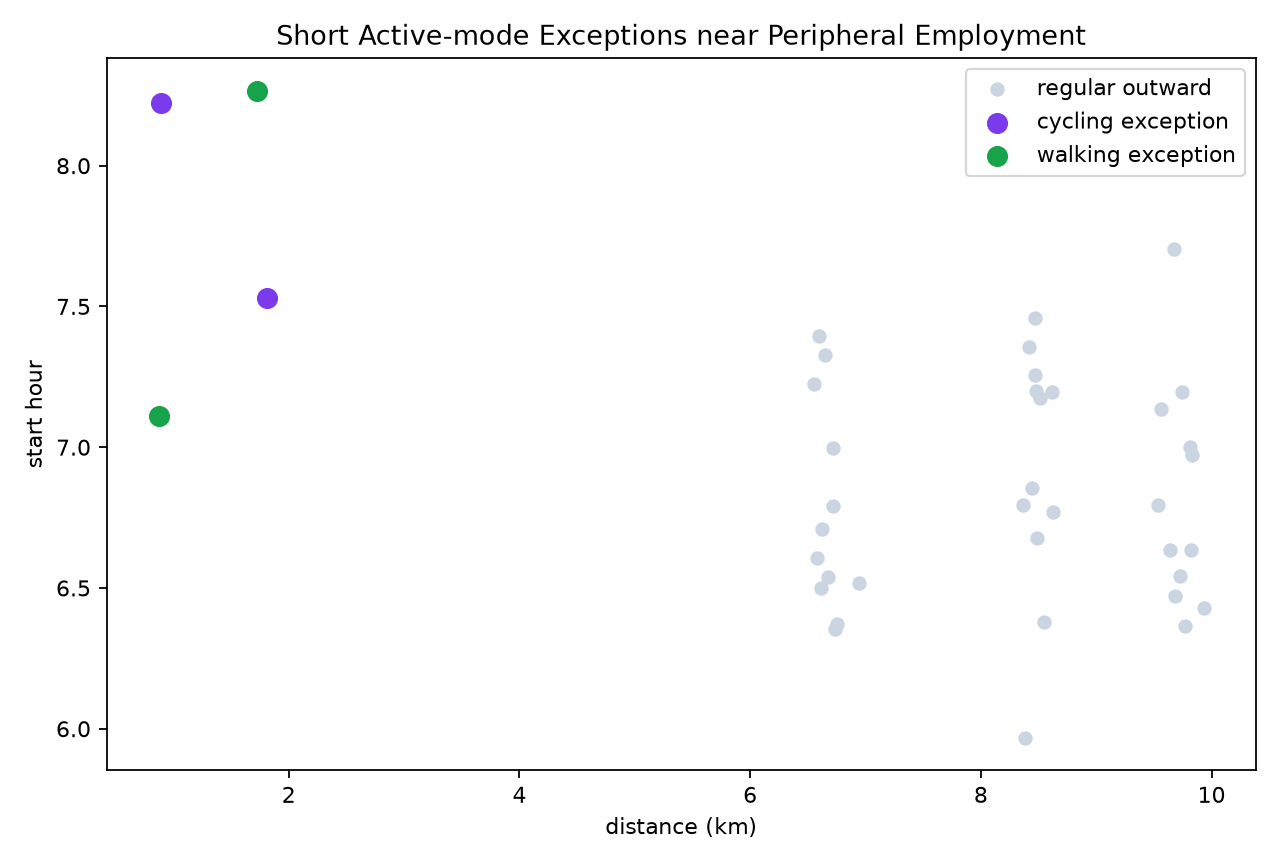

In [ ]:
df[df.flow_group.eq('outward')].groupby(['is_exception','mode_group']).distance_km.agg(['count','median','max'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/short_outward_active_exceptions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "outward_active_exception",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Short Active-mode Outward Exceptions",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/short_outward_active_exceptions.png"
  },
  "question": "Which outward work trips depart from the usual motorized, longer-distance pattern?",
  "code": "df[df.flow_group.eq('outward')].groupby(['is_exception','mode_group']).distance_km.agg(['count','median','max'])",
  "insight": "A few short outward commutes near peripheral employment zones use walking or cycling, forming exceptions to the otherwise motorized pattern",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "transport_mode",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 17)

Most weekday work trips flow inward to central employment and use a diverse mode mix. Outward commuters leave earlier, travel farther, rely more on motor vehicles, and repeatedly share a small corridor set; four short active trips form clear local exceptions.